# SADP: simulação básica da comunicação RS485 / Modbus-RTU

Este notebook simula, de forma simplificada, a conversa entre o **controlador** (placa NUCLEO-G0B1RE, que atua como mestre Modbus) e os **sensores ultrassônicos** DYP-A02YY4W-V2 (escravos) em um tronco RS485 do SADP.

O objetivo é entender, antes da bancada, **quanto tempo leva para ler todos os sensores de um lado do ônibus** e **o que pode dar errado no barramento**: endereços repetidos, quadros que colidem, sensores que não respondem.

**O que é simulado**
- Os bytes reais dos quadros Modbus-RTU, com o CRC-16, como descritos no documento de interfaces do fabricante.
- O tempo que cada quadro ocupa no fio a 9600 bps.
- O tempo de resposta do sensor (cerca de 100 ms, segundo o fabricante).
- Colisões: o RS485 é meia-dupla, então dois quadros ao mesmo tempo se perdem.
- Duas estratégias de consulta do mestre e algumas falhas de sensor.

**O que não é simulado**
- Nível elétrico, ruído, reflexões, terminação e polarização do barramento.
- Interferência acústica entre sensores que medem ao mesmo tempo.
- O comportamento real do sensor abaixo de 3 cm, que ainda será medido.

Todos os números aqui são **estimativas** para orientar os testes de bancada (T3, T4 e T7 do plano de testes), e não resultados de medição.

## 1. Visão geral da arquitetura

```
             tronco esquerdo (RS485, Modbus-RTU, 9600 bps)
NUCLEO ──┬── S01 ── S02 ── S03 ── ... ── S10
(mestre) │
         ├── tronco direito: S11 ... S20
         │
         └── enlace da tela (ESP32-S3)
```

- Cada lado do ônibus tem um **tronco** com 10 sensores no mesmo par de fios.
- O barramento é **meia-dupla**: só um dispositivo pode transmitir por vez. O mestre pergunta e o sensor responde.
- Cada sensor tem um **endereço** (1 a 254). Ele só responde às consultas com o seu endereço.
- O sensor **só mede quando é consultado** e leva cerca de 100 ms para responder. Esse é o tempo que domina o ciclo.

O notebook está dividido nos componentes da simulação (seções 2 a 6) e nos experimentos feitos com eles (seções 7 a 10).

## 2. Parâmetros

Os valores vêm do documento de interfaces do fabricante (velocidade, registradores, tempo de resposta) ou são escolhas da simulação (tempo-limite do mestre).

| Parâmetro | Valor | Origem |
|---|---|---|
| Velocidade | 9600 bps, 8 bits, sem paridade, 1 stop bit | fabricante (fixa) |
| Bits por byte no fio | 10 (start + 8 dados + stop) | padrão UART |
| Silêncio entre quadros | 3,5 caracteres | padrão Modbus-RTU |
| Tempo de resposta do sensor | cerca de 100 ms (registrador 0x0101) | fabricante |
| Tempo-limite do mestre | 200 ms após a consulta | escolha da simulação |
| Registrador da distância | 0x0101, valor em mm | fabricante |
| Registrador do endereço | 0x0200 | fabricante |

In [1]:
import heapq
import random
from dataclasses import dataclass, field
from typing import Callable, Dict, List, Optional

BAUD = 9600
BITS_POR_BYTE = 10                 # 1 start + 8 dados + 1 stop, sem paridade
T_CHAR = BITS_POR_BYTE / BAUD      # ~1,04 ms por byte
T_SILENCIO = 3.5 * T_CHAR          # intervalo mínimo entre quadros Modbus-RTU
RESPOSTA_S = 0.100                 # sensor: ~100 ms do fim da consulta à resposta (0x0101)
TIMEOUT_S = 0.200                  # mestre: tempo-limite após o fim da consulta
REG_TEMPO_REAL = 0x0101            # distância em mm, valor em tempo real
REG_ENDERECO = 0x0200              # endereço do escravo
ENDERECO_FABRICA = 0x01
BROADCAST = 0xFF                   # endereço de broadcast do fabricante

print(f'tempo de 1 byte: {T_CHAR*1000:.3f} ms | silêncio entre quadros: {T_SILENCIO*1000:.2f} ms')

tempo de 1 byte: 1.042 ms | silêncio entre quadros: 3.65 ms


## 3. Componente 1: o quadro Modbus-RTU

Toda conversa no barramento é feita em **quadros**: sequências de bytes com um formato fixo. O SADP usa dois tipos.

**Consulta de leitura (mestre → sensor), 8 bytes**

| Byte | Campo | Exemplo | Significado |
|---|---|---|---|
| 1 | Endereço | `01` | qual sensor deve responder |
| 2 | Função | `03` | ler registradores |
| 3 a 4 | Registrador | `01 01` | 0x0101, distância em tempo real |
| 5 a 6 | Quantidade | `00 01` | ler 1 registrador |
| 7 a 8 | CRC | `D4 36` | verificação de erro |

**Resposta (sensor → mestre), 7 bytes**

| Byte | Campo | Exemplo | Significado |
|---|---|---|---|
| 1 | Endereço | `01` | quem está respondendo |
| 2 | Função | `03` | repete a função pedida |
| 3 | Nº de bytes | `02` | 2 bytes de dado |
| 4 a 5 | Valor | `04 D2` | 0x04D2 = 1234 mm |
| 6 a 7 | CRC | `3A D9` | verificação de erro |

**CRC-16/MODBUS.** É uma "assinatura" calculada sobre os bytes do quadro. Quem recebe recalcula o CRC e compara. Se um bit mudou no caminho, ou se dois quadros se sobrepuseram, o CRC não bate e o quadro é descartado. O CRC vai com o byte baixo primeiro.

In [2]:
def crc16_modbus(data: bytes) -> int:
    crc = 0xFFFF
    for b in data:
        crc ^= b
        for _ in range(8):
            crc = (crc >> 1) ^ 0xA001 if crc & 1 else crc >> 1
    return crc


def com_crc(corpo: bytes) -> bytes:
    c = crc16_modbus(corpo)
    return corpo + bytes([c & 0xFF, c >> 8])          # CRC: byte baixo primeiro


def crc_ok(quadro: bytes) -> bool:
    return len(quadro) >= 4 and crc16_modbus(quadro[:-2]) == (quadro[-2] | quadro[-1] << 8)

# Conferência com o valor de teste padrão do CRC-16/MODBUS
assert crc16_modbus(b'123456789') == 0x4B37
print('CRC conferido: 0x%04X' % crc16_modbus(b'123456789'))

CRC conferido: 0x4B37


Funções que montam os quadros. `escrita_registrador` usa a função 0x06, que serve para gravar o endereço do sensor no registrador 0x0200.

In [3]:
def consulta_leitura(end: int, reg: int = REG_TEMPO_REAL, qtd: int = 1) -> bytes:
    return com_crc(bytes([end, 0x03, reg >> 8, reg & 0xFF, qtd >> 8, qtd & 0xFF]))


def resposta_leitura(end: int, valor: int) -> bytes:
    return com_crc(bytes([end, 0x03, 0x02, valor >> 8 & 0xFF, valor & 0xFF]))


def escrita_registrador(end: int, reg: int, valor: int) -> bytes:
    return com_crc(bytes([end, 0x06, reg >> 8, reg & 0xFF, valor >> 8, valor & 0xFF]))


def hexa(q: bytes) -> str:
    return " ".join(f"{b:02X}" for b in q)


def duracao(q: bytes) -> float:
    return len(q) * T_CHAR

q = consulta_leitura(0x01)
r = resposta_leitura(0x01, 1234)
print('consulta:', hexa(q), '| CRC ok?', crc_ok(q))
print('resposta:', hexa(r), '| CRC ok?', crc_ok(r))
print('valor lido:', r[3] << 8 | r[4], 'mm')

# Um único bit trocado no caminho faz o CRC falhar
estragado = bytearray(r); estragado[4] ^= 0x01
print('resposta com 1 bit trocado:', hexa(bytes(estragado)), '| CRC ok?', crc_ok(bytes(estragado)))

consulta: 01 03 01 01 00 01 D4 36 | CRC ok? True
resposta: 01 03 02 04 D2 3A D9 | CRC ok? True
valor lido: 1234 mm
resposta com 1 bit trocado: 01 03 02 04 D3 3A D9 | CRC ok? False


## 4. Componente 2: o tempo no barramento

A 9600 bps, cada byte ocupa 10 bits no fio, ou cerca de **1,04 ms**. Então:

- consulta de 8 bytes ≈ **8,3 ms**
- resposta de 7 bytes ≈ **7,3 ms**
- silêncio entre quadros ≈ **3,6 ms**

O que domina o tempo **não é o fio**, e sim a espera de cerca de **100 ms** pela medição do sensor. Consultando um sensor por vez, cada sensor custa cerca de 119 ms, e 10 sensores custam cerca de 1,2 s.

In [4]:
q, r = consulta_leitura(1), resposta_leitura(1, 1000)
por_sensor = duracao(q) + RESPOSTA_S + duracao(r) + T_SILENCIO
print(f'consulta: {duracao(q)*1000:.2f} ms | resposta: {duracao(r)*1000:.2f} ms')
print(f'por sensor (consulta + espera + resposta + silêncio): {por_sensor*1000:.1f} ms')
print(f'10 sensores, um de cada vez: {10*por_sensor:.2f} s')
print(f'parte do tempo gasta esperando o sensor: {RESPOSTA_S/por_sensor:.0%}')

consulta: 8.33 ms | resposta: 7.29 ms
por sensor (consulta + espera + resposta + silêncio): 119.3 ms
10 sensores, um de cada vez: 1.19 s
parte do tempo gasta esperando o sensor: 84%


## 5. Componente 3: o sensor (escravo)

A classe `Sensor` imita o comportamento do DYP-A02 descrito pelo fabricante:

- **Ignora** quadros endereçados a outro sensor. Aceita também o endereço de broadcast 0xFF.
- Na **leitura** (função 0x03, registrador 0x0101), mede a distância naquele instante e responde depois de `RESPOSTA_S`, com uma variação aleatória de até `±jitter_s`. A medida tem o erro da folha de dados, ±(1 + 0,3 % da distância) cm.
- Na **gravação de endereço** (função 0x06, registrador 0x0200), troca o próprio endereço e devolve o quadro como eco, como manda o Modbus.
- **Falhas configuráveis:**
  - `mudo=True`: o sensor nunca responde.
  - `zona_cega`: o que acontece abaixo de 3 cm. Pode ser `"silencio"` (não responde) ou `"zero"` (devolve 0 mm). Ainda não sabemos qual é o real; isso é o teste T3.
- `distancia_cm` é uma função do tempo, então dá para simular um obstáculo se aproximando.

In [5]:
@dataclass
class Sensor:
    nome: str
    endereco: int = ENDERECO_FABRICA
    distancia_cm: Callable[[float], float] = lambda t: 200.0
    mudo: bool = False                 # falha: não responde nunca
    zona_cega: str = "silencio"        # abaixo de 3 cm: "silencio" ou "zero" (a confirmar, T3)
    jitter_s: float = 0.002            # variação do tempo de resposta (a medir, T4)
    rng: random.Random = field(default_factory=lambda: random.Random(1))

    def responder(self, consulta: bytes, t_fim: float):
        """Recebe um quadro íntegro e devolve (atraso, quadro) ou None."""
        if self.mudo or len(consulta) < 8:
            return None
        end, func = consulta[0], consulta[1]
        if end not in (self.endereco, BROADCAST):
            return None                                    # quadro de outro escravo
        reg = consulta[2] << 8 | consulta[3]
        if func == 0x03 and reg == REG_TEMPO_REAL:
            d = self.distancia_cm(t_fim)
            if d < 3.0:
                if self.zona_cega == "silencio":
                    return None
                mm = 0
            else:
                erro = (1 + 0.003 * d) * self.rng.uniform(-1, 1)   # ±(1 + 0,3% S) cm
                mm = int(round(min(450.0, d + erro) * 10))
            atraso = RESPOSTA_S + self.rng.uniform(-self.jitter_s, self.jitter_s)
            return atraso, resposta_leitura(self.endereco, mm)
        if func == 0x06 and reg == REG_ENDERECO:
            novo = consulta[5]
            self.endereco = novo
            return 0.010, consulta                          # eco da escrita (Modbus)
        return None

s = Sensor('S01', endereco=0x01, distancia_cm=lambda t: 87.0)
atraso, resp = s.responder(consulta_leitura(0x01), 0.0)
print(f'consulta ao 0x01 -> responde em {atraso*1000:.1f} ms com {hexa(resp)} ({(resp[3] << 8 | resp[4])/10} cm)')
print('consulta ao 0x02 ->', s.responder(consulta_leitura(0x02), 0.0), '(ignorada)')
s.mudo = True
print('sensor mudo      ->', s.responder(consulta_leitura(0x01), 0.0))

consulta ao 0x01 -> responde em 101.4 ms com 01 03 02 03 5D 79 4D (86.1 cm)
consulta ao 0x02 -> None (ignorada)
sensor mudo      -> None


## 6. Componente 4: o barramento e o mestre

### Simulação por eventos
Em vez de avançar o tempo em passos fixos, a simulação mantém uma **agenda de eventos** ordenada pelo tempo (`heapq`). Os eventos são de dois tipos:

- **`fim_tx`**: um quadro terminou de ser transmitido. Nesse momento a simulação verifica se ele **se sobrepôs** a outro quadro. Se sim, o quadro está corrompido, e o CRC falharia no receptor.
- **`timeout`**: o mestre desistiu de esperar a resposta de um sensor.

Cada quadro no fio é um objeto `Tx` (origem, início, fim, bytes). Ele entra na lista do barramento **assim que é agendado**. Assim, quando um quadro termina, todos os que poderiam se sobrepor a ele já são conhecidos.

### Regra de colisão (meia-dupla)
Se dois quadros ocupam o fio ao mesmo tempo, **os dois se perdem**. Isso vale para duas respostas simultâneas, como na resposta de dois sensores com o mesmo endereço. Vale também para uma resposta que chega enquanto o mestre ainda está transmitindo. Um quadro do mestre corrompido não é entendido por nenhum sensor, e nenhum sensor responde a ele.

### Estratégias do mestre (`ciclo`)
- **`"sequencial"`**: envia a consulta, espera a resposta (ou o tempo-limite) e só então consulta o próximo sensor. É simples e seguro, mas lento: cerca de 1,2 s para 10 sensores.
- **`"pipeline"`**: envia todas as consultas em seguida, separadas por `intervalo`, sem esperar as respostas. Os sensores medem quase ao mesmo tempo e as respostas chegam em fila. É muito mais rápido, mas as respostas não podem colidir com as consultas nem entre si.

`gravar_endereco` envia a função 0x06 para trocar o endereço de um sensor. Deve haver só um sensor com aquele endereço no barramento.

In [6]:
@dataclass
class Tx:
    origem: str          # "mestre" ou nome do sensor
    inicio: float
    fim: float
    quadro: bytes
    alvo: int = 0        # endereço consultado (para o log)
    corrompido: bool = False

class Barramento:
    """Um enlace RS485 meia-dupla com um mestre e vários sensores."""

    def __init__(self, sensores: List[Sensor], nome: str = "tronco"):
        self.sensores, self.nome = sensores, nome
        self.txs: List[Tx] = []
        self._ev: list = []
        self._n = 0

    # -- infraestrutura de eventos
    def _agenda(self, t, tipo, dado):
        self._n += 1
        heapq.heappush(self._ev, (t, self._n, tipo, dado))

    def _transmite(self, origem, t0, quadro, alvo=0) -> Tx:
        tx = Tx(origem, t0, t0 + duracao(quadro), quadro, alvo)
        self.txs.append(tx)                       # entra na lista ao ser agendado
        self._agenda(tx.fim, "fim_tx", tx)
        return tx

    def _sobreposto(self, tx: Tx) -> bool:
        return any(o is not tx and o.inicio < tx.fim and o.fim > tx.inicio for o in self.txs)

    # -- ciclo de leitura
    def ciclo(self, enderecos: List[int], estrategia: str = "sequencial",
              t0: float = 0.0, intervalo: float = T_SILENCIO) -> Dict:
        """Lê os endereços dados uma vez. Devolve leituras (cm ou None) e tempos."""
        self.txs, self._ev = [], []
        leituras: Dict[int, Optional[float]] = {e: None for e in enderecos}
        erros_crc: List[int] = []
        fila = list(enderecos)
        estado = {"atual": None, "fim": t0}

        def envia(t, end):
            estado["atual"] = end
            tx = self._transmite("mestre", t, consulta_leitura(end), end)
            self._agenda(tx.fim + TIMEOUT_S, "timeout", end)

        if estrategia == "sequencial":
            envia(t0, fila.pop(0))
        elif estrategia == "pipeline":
            t = t0
            for end in fila:
                q = consulta_leitura(end)
                self._transmite("mestre", t, q, end)
                t += duracao(q) + intervalo
            fila = []
        else:
            raise ValueError(estrategia)

        pendentes = set(enderecos)
        while self._ev:
            t, _, tipo, dado = heapq.heappop(self._ev)
            if tipo == "fim_tx":
                tx: Tx = dado
                tx.corrompido = self._sobreposto(tx)
                estado["fim"] = max(estado["fim"], t)
                if tx.origem == "mestre":
                    if estrategia == "pipeline":
                        self._agenda(t + TIMEOUT_S, "timeout", tx.alvo)
                    if tx.corrompido:
                        continue                        # nenhum sensor entende o quadro
                    for s in self.sensores:
                        r = s.responder(tx.quadro, t)
                        if r:
                            atraso, q = r
                            self._transmite(s.nome, t + atraso, q, tx.alvo)
                else:
                    end = tx.alvo
                    if tx.corrompido or not crc_ok(tx.quadro):
                        erros_crc.append(end)
                    elif end in pendentes and tx.quadro[1] == 0x03:
                        leituras[end] = (tx.quadro[3] << 8 | tx.quadro[4]) / 10.0
                        pendentes.discard(end)
                        if estrategia == "sequencial" and estado["atual"] == end and fila:
                            envia(t + T_SILENCIO, fila.pop(0))
            elif tipo == "timeout":
                end = dado
                if estrategia == "sequencial" and estado["atual"] == end:
                    if end in pendentes:
                        pendentes.discard(end)          # sem resposta
                        estado["fim"] = max(estado["fim"], t)
                        if fila:
                            envia(t, fila.pop(0))
                elif estrategia == "pipeline" and end in pendentes:
                    pendentes.discard(end)
                    estado["fim"] = max(estado["fim"], t)
        return {"leituras": leituras, "duracao": estado["fim"] - t0,
                "erros_crc": sorted(set(erros_crc)), "txs": list(self.txs)}

    def gravar_endereco(self, atual: int, novo: int) -> Dict:
        """Envia a função 0x06 no registrador 0x0200 (deve haver só um sensor ligado)."""
        self.txs, self._ev = [], []
        q = escrita_registrador(atual, REG_ENDERECO, novo)
        self._transmite("mestre", 0.0, q, atual)
        eco = None
        while self._ev:
            t, _, tipo, tx = heapq.heappop(self._ev)
            tx.corrompido = self._sobreposto(tx)
            if tx.origem == "mestre" and not tx.corrompido:
                for s in self.sensores:
                    r = s.responder(tx.quadro, t)
                    if r:
                        self._transmite(s.nome, t + r[0], r[1], atual)
            elif tx.origem != "mestre" and not tx.corrompido and crc_ok(tx.quadro):
                eco = tx.quadro
        return {"consulta": q, "eco": eco}

## 7. Funções auxiliares

`tronco(n)` monta um tronco com `n` sensores, com endereços em sequência e obstáculos fixos sorteados entre 12 cm e 4,5 m. `resumo` imprime uma linha por ciclo. `linha_do_tempo` desenha quem ocupou o fio e quando.

In [7]:
def tronco(n: int, jitter: float = 0.002, primeiro: int = 1, semente: int = 7) -> List[Sensor]:
    rng = random.Random(semente)
    dist = [rng.choice([450.0, 180.0, 95.0, 40.0, 25.0, 12.0]) for _ in range(n)]
    return [Sensor(f"S{primeiro + i:02d}", primeiro + i, (lambda d: (lambda t: d))(dist[i]),
                   jitter_s=jitter, rng=random.Random(semente + i)) for i in range(n)]


def resumo(titulo: str, r: Dict):
    lidas = sum(v is not None for v in r["leituras"].values())
    perd = [f"{e:02d}" for e, v in r["leituras"].items() if v is None]
    print(f"  {titulo:<44} ciclo {r['duracao'] * 1000:7.1f} ms   "
          f"lidos {lidas:2d}/{len(r['leituras'])}"
          + (f"   sem leitura: {', '.join(perd)}" if perd else ""))


import matplotlib.pyplot as plt
from matplotlib.patches import Patch

AZUL, LARANJA, CRITICO = '#2a78d6', '#eb6834', '#d03b3b'   # consulta, resposta, colisão
TINTA2, GRADE, FUNDO = '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': FUNDO, 'axes.facecolor': FUNDO, 'axes.edgecolor': GRADE,
                     'axes.labelcolor': TINTA2, 'xtick.color': TINTA2, 'ytick.color': TINTA2,
                     'font.size': 9.5, 'axes.spines.top': False, 'axes.spines.right': False})

def linha_do_tempo(casos):
    # casos: lista de (titulo, resultado de Barramento.ciclo)
    fig, axs = plt.subplots(len(casos), 1, figsize=(10, 2.4 * len(casos) + 0.6),
                            constrained_layout=True, squeeze=False)
    for ax, (tit, r) in zip(axs[:, 0], casos):
        nomes = ['mestre'] + sorted({t.origem for t in r['txs'] if t.origem != 'mestre'})
        y = {n: i for i, n in enumerate(nomes)}
        for t in r['txs']:
            cor = CRITICO if t.corrompido else (AZUL if t.origem == 'mestre' else LARANJA)
            ax.barh(y[t.origem], (t.fim - t.inicio) * 1000, left=t.inicio * 1000, height=0.6,
                    color=cor, hatch='////' if t.corrompido else None, edgecolor=FUNDO, linewidth=0.8)
        ax.set_yticks(range(len(nomes)), nomes)
        ax.invert_yaxis()
        ax.grid(axis='x', color=GRADE, linewidth=0.6); ax.set_axisbelow(True)
        ax.set_title(f"{tit}: ciclo de {r['duracao']*1000:.0f} ms", loc='left', fontsize=10.5)
        ax.set_xlim(0, max(r['duracao'] * 1000 * 1.02, 250))
    axs[-1, 0].set_xlabel('tempo (ms)')
    fig.legend(handles=[Patch(color=AZUL, label='consulta do mestre'),
                        Patch(color=LARANJA, label='resposta do sensor'),
                        Patch(facecolor=CRITICO, hatch='////', edgecolor=FUNDO, label='quadro perdido (colisão)')],
               loc='outside upper right', ncol=3, frameon=False)
    plt.show()

## 8. Experimento 1: endereços

Os sensores **saem de fábrica com o mesmo endereço (0x01)**. Se dois deles forem ligados ao mesmo tronco sem reprogramação, os dois respondem à mesma consulta ao mesmo tempo, as respostas colidem e o mestre não lê nenhum dos dois.

Por isso o endereço precisa ser gravado **com um sensor por vez no barramento**, antes de montar o tronco. É o procedimento de gravação e etiquetagem previsto no teste T2.

In [8]:
a, b = Sensor('A'), Sensor('B')                       # os dois com 0x01 de fábrica
r = Barramento([a, b]).ciclo([0x01])
print('dois sensores com 0x01 -> leitura:', r['leituras'][1], '| erro de CRC em', r['erros_crc'])

g = Barramento([a]).gravar_endereco(0x01, 0x05)        # só o sensor A ligado
print('gravação:', hexa(g['consulta']), '-> eco', hexa(g['eco']), f'| novo endereço de A = 0x{a.endereco:02X}')

r = Barramento([a, b]).ciclo([0x01, 0x05])
print('depois da gravação -> leituras:', r['leituras'])

dois sensores com 0x01 -> leitura: None | erro de CRC em [1]
gravação: 01 06 02 00 00 05 48 71 -> eco 01 06 02 00 00 05 48 71 | novo endereço de A = 0x05
depois da gravação -> leituras: {1: 200.8, 5: 200.8}


### 8.1 Procedimento de endereçamento

Rotina para endereçar cada A02YY4W antes de montar o tronco (teste T2). Para cada sensor:

1. Ligue **só aquele sensor** ao mestre.
2. **Descubra o endereço atual** com uma leitura pelo broadcast `0xFF`. Com um único sensor ligado, ele responde com o próprio endereço no primeiro byte da resposta. Isso serve também para sensores já usados, cujo endereço não se sabe. Se não houver resposta válida, há outro sensor ligado (as respostas colidiram) ou o sensor não está alimentado.
3. **Grave o endereço novo** no registrador 0x0200 (função 0x06) e confira se o eco é igual à consulta.
4. **Confirme** com uma leitura de distância no endereço novo.
5. **Etiquete** o sensor com o nome e o endereço.

Plano de endereços sugerido: lado esquerdo S01 a S10 = 0x01 a 0x0A e lado direito S11 a S20 = 0x0B a 0x14. Os endereços são únicos no ônibus inteiro, o que permite trocar um sensor de lado sem regravar.

Na bancada, desligue e religue o sensor depois da gravação e leia de novo no endereço novo. Isso confirma que o endereço ficou salvo. Rodar a rotina de novo num sensor já endereçado não muda nada: ela só confere.

In [ ]:
PLANO_ESQUERDO = {f"S{i:02d}": i for i in range(1, 11)}      # etiqueta -> endereço


def descobrir_endereco(bus: Barramento) -> Optional[int]:
    """Lê pelo broadcast 0xFF e devolve o endereço de quem respondeu."""
    r = bus.ciclo([BROADCAST])
    validas = [t for t in r['txs'] if t.origem != 'mestre' and not t.corrompido and crc_ok(t.quadro)]
    return validas[0].quadro[0] if len(validas) == 1 else None


def enderecar(sensor: Sensor, novo: int, outros: List[Sensor] = ()) -> int:
    """Grava `novo` no sensor e confere. `outros` simula sensores esquecidos no barramento."""
    if not 1 <= novo <= 254:
        raise ValueError(f'endereço fora da faixa 1 a 254: {novo}')
    bus = Barramento([sensor, *outros])
    atual = descobrir_endereco(bus)
    if atual is None:
        raise RuntimeError('nenhuma resposta válida: sensor desligado ou mais de um sensor no barramento')
    if atual != novo:
        g = bus.gravar_endereco(atual, novo)
        if g['eco'] != g['consulta']:
            raise RuntimeError(f'{sensor.nome}: eco da gravação não confere')
    if bus.ciclo([novo])['leituras'][novo] is None:
        raise RuntimeError(f'{sensor.nome}: não respondeu no endereço novo 0x{novo:02X}')
    return atual

# 10 sensores novos, todos com o endereço de fábrica
caixa = [Sensor(etiqueta, rng=random.Random(i)) for i, etiqueta in enumerate(PLANO_ESQUERDO)]
for s, novo in zip(caixa, PLANO_ESQUERDO.values()):
    antes = enderecar(s, novo)                                  # só este sensor ligado
    print(f'{s.nome}: 0x{antes:02X} -> 0x{novo:02X}  ok, etiquetar')

print()
resumo('tronco montado com os sensores endereçados', Barramento(caixa).ciclo(list(PLANO_ESQUERDO.values())))

# Erro comum: um segundo sensor esquecido no barramento durante a gravação
try:
    enderecar(Sensor('novo'), 0x0B, outros=[Sensor('esquecido')])
except RuntimeError as e:
    print('\ncom dois sensores ligados:', e)

### Versão para a bancada

A mesma rotina, falando com o sensor real por um **conversor USB-RS485** ligado ao computador. Ela usa a biblioteca `pyserial` e reaproveita as funções de quadro e CRC da seção 3.

- Ligue A, B, GND e a alimentação de **um único sensor** no conversor.
- Descubra a porta no Gerenciador de Dispositivos do Windows (algo como `COM5`).
- Use um conversor com **controle automático de direção**. A maioria dos conversores USB-RS485 baratos já faz isso.
- Se o sensor responder com exceção Modbus (função com o bit 0x80 ligado), a rotina avisa.

A célula abaixo só define as funções. As chamadas ficam comentadas, para que o notebook continue rodando sem o hardware.

In [ ]:
import time

try:
    import serial                      # pip install pyserial
except ImportError:
    serial = None


def abrir_porta(porta: str):
    return serial.Serial(porta, BAUD, bytesize=8, parity='N', stopbits=1, timeout=TIMEOUT_S + 0.1)


def transacao(ser, quadro: bytes, n_esperado: int) -> Optional[bytes]:
    """Envia um quadro e espera a resposta. Devolve None se não chegar nada íntegro."""
    ser.reset_input_buffer()
    ser.write(quadro)
    ser.flush()
    resp = ser.read(n_esperado)
    if len(resp) == 5 and resp[1] & 0x80 and crc_ok(resp):
        raise RuntimeError(f'o sensor recusou o comando (exceção Modbus 0x{resp[2]:02X})')
    return resp if len(resp) == n_esperado and crc_ok(resp) else None


def enderecar_bancada(porta: str, novo: int) -> int:
    """Mesmo procedimento de `enderecar`, mas com o sensor real. Só um sensor ligado."""
    if not 1 <= novo <= 254:
        raise ValueError(f'endereço fora da faixa 1 a 254: {novo}')
    with abrir_porta(porta) as ser:
        r = transacao(ser, consulta_leitura(BROADCAST), 7)
        if r is None:
            raise RuntimeError('nenhuma resposta válida: confira A/B, alimentação, ou se há mais de um sensor ligado')
        atual = r[0]
        if atual != novo:
            q = escrita_registrador(atual, REG_ENDERECO, novo)
            if transacao(ser, q, 8) != q:
                raise RuntimeError('eco da gravação não confere')
            time.sleep(0.2)
        r = transacao(ser, consulta_leitura(novo), 7)
        if r is None:
            raise RuntimeError(f'não respondeu no endereço novo 0x{novo:02X}')
        print(f'0x{atual:02X} -> 0x{novo:02X} ok, distância lida: {(r[3] << 8 | r[4]) / 10} cm')
        return atual

print('pyserial disponível' if serial else 'pyserial não instalado: rode  pip install pyserial  antes da bancada')

# Na bancada, um sensor por vez (troque COM5 pela porta do conversor):
# enderecar_bancada('COM5', 0x01)
# enderecar_bancada('COM5', 0x02)
# ...

## 9. Experimento 2: sequencial x pipeline

Comparamos três formas de ler 10 sensores de um lado:

1. **Sequencial, 1 linha**: um sensor de cada vez.
2. **Pipeline, 1 linha com 10**: as 10 consultas em seguida.
3. **Pipeline, 2 linhas com 5**: cada lado dividido em duas linhas RS485, cada uma com sua UART no STM32, lidas ao mesmo tempo.

In [9]:
ends = list(range(1, 11))
seq   = Barramento(tronco(10)).ciclo(ends, 'sequencial')
pip10 = Barramento(tronco(10)).ciclo(ends, 'pipeline')
l1 = Barramento(tronco(5, primeiro=1)).ciclo(list(range(1, 6)), 'pipeline')
l2 = Barramento(tronco(5, primeiro=6, semente=8)).ciclo(list(range(6, 11)), 'pipeline')

resumo('sequencial, 1 linha', seq)
resumo('pipeline, 1 linha com 10', pip10)
print(f"  {'pipeline, 2 linhas com 5 (em paralelo)':<44} ciclo {max(l1['duracao'], l2['duracao'])*1000:7.1f} ms")
print()
print('leituras do ciclo sequencial (cm):')
print('  ' + '  '.join(f'S{e:02d}={v:.1f}' for e, v in seq['leituras'].items()))

  sequencial, 1 linha                          ciclo  1189.1 ms   lidos 10/10
  pipeline, 1 linha com 10                     ciclo   316.1 ms   lidos  8/10   sem leitura: 01, 10
  pipeline, 2 linhas com 5 (em paralelo)       ciclo   164.2 ms

leituras do ciclo sequencial (cm):
  S01=94.5  S02=179.2  S03=39.9  S04=12.1  S05=449.8  S06=449.9  S07=24.5  S08=448.2  S09=96.2  S10=24.7


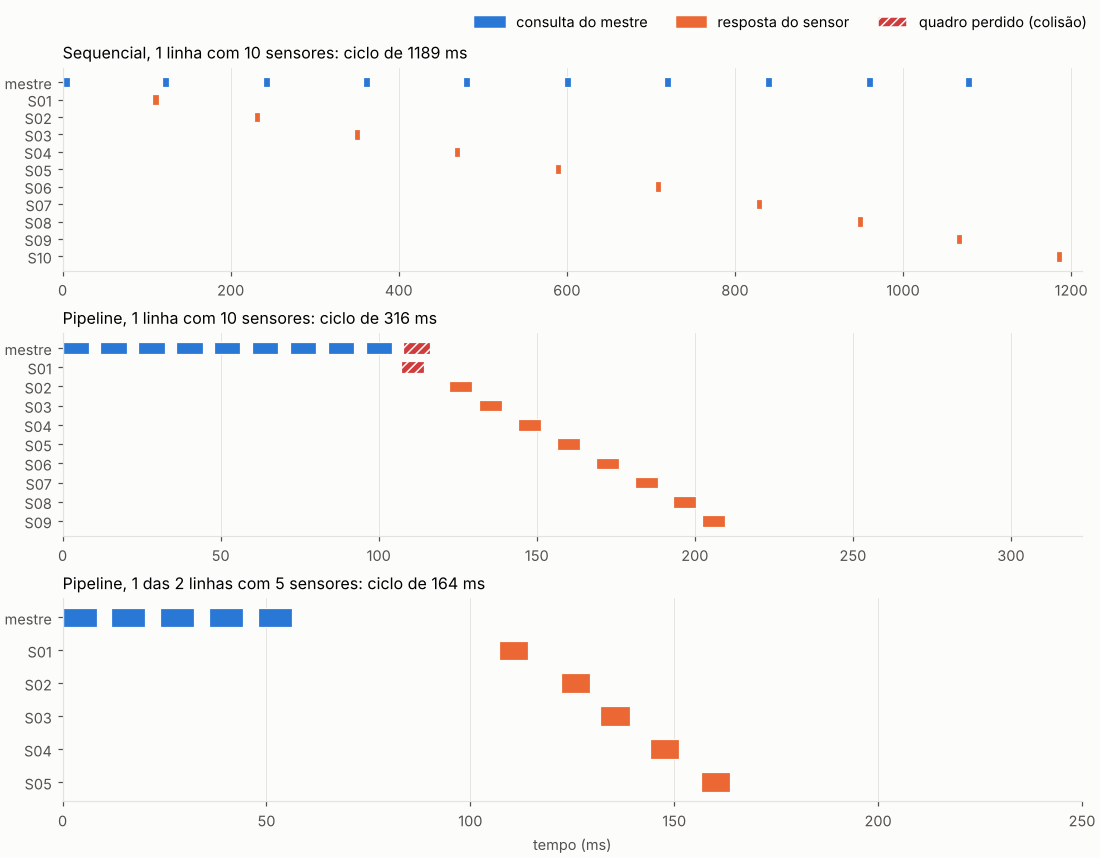

In [10]:
linha_do_tempo([('Sequencial, 1 linha com 10 sensores', seq),
                ('Pipeline, 1 linha com 10 sensores', pip10),
                ('Pipeline, 1 das 2 linhas com 5 sensores', l1)])

**Como ler a figura.** Cada linha é um dispositivo e cada barra é um quadro no fio: azul é a consulta do mestre, laranja é a resposta do sensor e vermelho hachurado é um quadro perdido.

- **Sequencial**: o fio fica quase todo o tempo **parado**, esperando os 100 ms de cada medição. O ciclo dá cerca de 1,19 s, igual à conta da seção 4.
- **Pipeline com 10**: as 10 consultas ocupam cerca de 116 ms. A resposta do S01 chega por volta de 108 ms, **enquanto o mestre ainda envia a consulta do S10**, e as duas se perdem. Resultado: o S01 e o S10 ficam sem leitura, e o ciclo se alonga por causa do tempo-limite.
- **Pipeline com 2 linhas de 5**: as 5 consultas terminam em cerca de 56 ms, bem antes da primeira resposta. O ciclo cai para cerca de **164 ms**, sem perdas.

**Regra prática:** no pipeline, todas as consultas de uma linha precisam terminar antes de a primeira resposta chegar:

$$n \cdot T_{consulta} + (n-1) \cdot \text{intervalo} \;<\; T_{consulta} + T_{resposta\,do\,sensor}$$

## 10. Experimento 3: variação do tempo de resposta (jitter)

O fabricante diz "cerca de 100 ms", mas **não informa quanto esse tempo varia**. No pipeline, as respostas chegam com cerca de 12 ms de distância umas das outras, e cada uma dura cerca de 7,3 ms. Se o tempo de resposta variar alguns milissegundos, duas respostas podem se sobrepor.

Aumentar o **intervalo entre consultas** afasta as respostas e protege contra essa variação. Mas, se o intervalo for grande demais, as consultas deixam de caber antes da primeira resposta, pela regra da seção anterior. A tabela mostra esse equilíbrio, com 200 ciclos por caso.

In [11]:
import math
jitters = (0.002, 0.005, 0.010)
print(f"{'intervalo':>10} | " + ' | '.join(f'jitter ±{j*1000:.0f} ms' for j in jitters))
print('-' * 62)
for gap in (T_SILENCIO, 0.010, 0.015, 0.020):
    cel = []
    for jit in jitters:
        ok = tot = 0; dur = 0.0
        for k in range(200):
            d = 0.0
            for p, sem in ((1, 10 + k), (6, 500 + k)):
                r = Barramento(tronco(5, jit, p, sem)).ciclo(list(range(p, p + 5)), 'pipeline', intervalo=gap)
                ok += sum(v is not None for v in r['leituras'].values()); tot += 5
                d = max(d, r['duracao'])
            dur += d
        cel.append(f'{100*(tot-ok)/tot:4.1f}% ({dur/200*1000:3.0f} ms)')
    print(f'{gap*1000:7.2f} ms | ' + ' | '.join(f'{c:>15}' for c in cel))

limite = (duracao(consulta_leitura(1)) + RESPOSTA_S - 5 * duracao(consulta_leitura(1))) / 4
print(f'\nmaior intervalo que ainda cabe antes da 1ª resposta (5 consultas, sem jitter): {limite*1000:.1f} ms')

 intervalo | jitter ±2 ms | jitter ±5 ms | jitter ±10 ms
--------------------------------------------------------------
   3.65 ms |   0.0% (164 ms) |  25.8% (230 ms) |  48.2% (247 ms)
  10.00 ms |   0.0% (190 ms) |   0.0% (191 ms) |  18.6% (239 ms)
  15.00 ms |   0.0% (210 ms) |   0.0% (211 ms) |  10.3% (247 ms)
  20.00 ms |  40.0% (322 ms) |  28.8% (314 ms) |  25.8% (308 ms)

maior intervalo que ainda cabe antes da 1ª resposta (5 consultas, sem jitter): 16.7 ms


**Leitura dos resultados** (perdas por colisão e ciclo médio entre parênteses):

- Com o intervalo padrão do Modbus (3,65 ms), o pipeline só funciona se o tempo de resposta variar **muito pouco** (±2 ms).
- Um intervalo de **10 a 15 ms** tolera cerca de ±5 ms sem perdas, com ciclo de 0,19 a 0,21 s.
- Com **20 ms**, a 5ª consulta já não cabe antes da primeira resposta e há perdas mesmo sem variação.

Ou seja, **o intervalo certo depende do jitter real do sensor, que só a bancada vai dizer** (teste T4).

## 11. Experimento 4: falhas de sensor

Dois casos em um tronco de 10 lido em sequência:

- **S04 mudo**: sensor queimado ou desconectado.
- **S07 a 2 cm**: obstáculo dentro da zona cega.

Para o S07, comparamos as duas hipóteses: o sensor fica em silêncio ou devolve 0 mm.

In [12]:
s = tronco(10)
s[3].mudo = True                          # S04
s[6].distancia_cm = lambda t: 2.0         # S07 encostado
r1 = Barramento(s).ciclo(ends, 'sequencial')
resumo('S04 mudo e S07 a 2 cm (zona cega = silêncio)', r1)
s[6].zona_cega = 'zero'
r2 = Barramento(s).ciclo(ends, 'sequencial')
resumo('o mesmo, mas a zona cega devolve 0 mm', r2)
print('\nleitura do S07 no segundo caso:', r2['leituras'][7], 'cm')

  S04 mudo e S07 a 2 cm (zona cega = silêncio) ciclo  1366.8 ms   lidos  8/10   sem leitura: 04, 07
  o mesmo, mas a zona cega devolve 0 mm        ciclo  1276.3 ms   lidos  9/10   sem leitura: 04

leitura do S07 no segundo caso: 0.0 cm


- Cada sensor que não responde **alonga o ciclo** em cerca de 100 ms, porque o mestre espera o tempo-limite antes de seguir.
- Se o sensor ficar **em silêncio** abaixo de 3 cm, o mestre não distingue "encostado" de "queimado". É por isso que a lógica fuzzy trata o silêncio de um sensor que estava perto como zona cega, e não como falha.
- Se o sensor devolver **0 mm**, a situação fica clara já na comunicação.

Qual dos dois acontece de verdade é o teste **T3** do plano de bancada.

## 12. Conclusões e próximos passos

| Pergunta | Resposta da simulação |
|---|---|
| Quanto leva ler 10 sensores, um por vez? | cerca de **1,19 s** |
| O pipeline numa linha só funciona? | **Não** com 10 sensores: a 1ª resposta colide com a última consulta |
| E com 2 linhas de 5 por lado? | cerca de **0,16 a 0,21 s**, dependendo do intervalo |
| O que decide o intervalo certo? | a **variação do tempo de resposta** do sensor, ainda não medida |
| Dá para ligar sensores com o endereço de fábrica juntos? | **Não**: gravar um por vez e etiquetar |

**O que medir na bancada para alimentar esta simulação**
- **T3**: o que o sensor devolve abaixo de 3 cm (silêncio, 0 ou outro valor).
- **T4**: o tempo de resposta real e a sua variação (jitter). Com esses dados, ajuste `RESPOSTA_S`, `jitter_s` e `intervalo`.
- **T7**: se sensores vizinhos medindo ao mesmo tempo se atrapalham. O pipeline faz isso acontecer, e a simulação não considera.

**Limitações:** a simulação considera o barramento ideal (sem ruído nem erros de bit) e não considera interferência acústica.

### Para experimentar
- Troque `RESPOSTA_S` e o `jitter_s` dos sensores pelos valores medidos e rode de novo os experimentos 2 e 3.
- Teste outros tamanhos de linha, por exemplo `tronco(4)` ou `tronco(3)`.
- Faça um obstáculo se aproximar: `distancia_cm=lambda t: 100 - 20*t`.
- Mude `TIMEOUT_S` e veja o efeito no experimento 4.